In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# Connect and Access Git Repository

import os
import sys
from getpass import getpass
from pathlib import Path

GITHUB_USERNAME = "sharaffatima"
REPO_NAME = "bachelor-thesis"



token = getpass("GitHub token: ")


REPO_URL = f"https://{token}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME


if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
sys.path.append(str(REPO_DIR))

print("Repo exists:", REPO_DIR.exists())

GitHub token: ··········
Cloning into '/content/bachelor-thesis'...
remote: Enumerating objects: 133, done.
remote: Counting objects: 100% (133/133), done.
remote: Compressing objects: 100% (98/98), done.
remote: Total 133 (delta 48), reused 103 (delta 25), pack-reused 0 (from 0)
Receiving objects: 100% (133/133), 87.85 KiB | 5.86 MiB/s, done.
Resolving deltas: 100% (48/48), done.
/content/bachelor-thesis
Repo exists: True


In [12]:
# Imports
import os
import numpy as np
import torch
from torch.utils.data import DataLoader


# global configuration

REPO_DIR = Path("/content/bachelor-thesis")
sys.path.append(str(REPO_DIR))

from utils.dataset import PTBXLTranADDataset
from explainability.attention import TranADExplainability
from utils.seed import set_seed, RANDOM_SEED
from models.tranad import TranADMainModel

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(RANDOM_SEED)
print(f"Active device: {DEVICE}")

Active device: cuda


In [4]:
# Load my preprocessed data


PROCESSED_DIR = Path("/content/drive/MyDrive/ECG data/processed")


X_train = np.load(os.path.join(PROCESSED_DIR, "X_train.npy"))
y_train = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))

X_val = np.load(os.path.join(PROCESSED_DIR, "X_val.npy"))
y_val = np.load(os.path.join(PROCESSED_DIR, "y_val.npy"))

X_test = np.load(os.path.join(PROCESSED_DIR, "X_test.npy"))
y_test = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))


print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(17418, 1000, 12)
(2183, 1000, 12)
(2198, 1000, 12)


In [16]:
# Training only on normal data

normal_train_mask = y_train == 0

X_train_normal = X_train[normal_train_mask]
y_train_normal = y_train[normal_train_mask]

In [48]:
# Datasets

train_dataset = PTBXLTranADDataset(
    X_train_normal,
    y_train_normal,
    normalize=True
)

val_dataset = PTBXLTranADDataset(
    X_val,
    y_val,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

test_dataset = PTBXLTranADDataset(
    X_test,
    y_test,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

In [49]:
# Dataloaders

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False
)

In [50]:
# Check the shapes

# Expected:
#         Batch X: torch.Size([16, 1000, 12])
#         Batch y: torch.Size([16])

batch_x, batch_y = next(iter(train_loader))

print(batch_x.shape)
print(batch_y.shape)

torch.Size([4, 1000, 12])
torch.Size([4])


In [33]:
# Create Model

TranAD = TranADMainModel(
    NumFeatures=12,
    ModelDimension=32,
    NumHeads=4,
    NumEncoderLayers=1,
    NumDecoderLayers=1,
    ForwardDimension=64,
    DropoutRate=0.1,
    LearningRate=1e-4,
    FocusGrowthRate=1.05,
    InitialFocusScore=1.0,
    MaxFocusScore=5.0,
    AnomalyPercentile=95.0,
)

TranADModel: 35,096 Parameter | d_model=32, H=4, Enc=1, Dec×2=1


In [34]:
# Test

batch_x = batch_x.to(TranAD.Device)

x1, x2 = TranAD.Network(batch_x)

print(x1.shape)
print(x2.shape)

torch.Size([4, 1000, 12])
torch.Size([4, 1000, 12])


In [35]:
# Training

print("\n── TranAD Training starts ─────────────────────────────")

TranAD.TrainModel(
    TrainingLoader = train_loader,
    NumEpochs      = 5,
    PrintInterval  = 1,
)


── TranAD Training starts ─────────────────────────────
Epoche    1/5 | Loss=1.47919 | φ=1.05 | LR=1.00e-04
Epoche    2/5 | Loss=0.87022 | φ=1.10 | LR=1.00e-04
Epoche    3/5 | Loss=0.69604 | φ=1.16 | LR=1.00e-04
Epoche    4/5 | Loss=0.60540 | φ=1.22 | LR=1.00e-04
Epoche    5/5 | Loss=0.54646 | φ=1.28 | LR=1.00e-04
Training complete.


In [51]:
# Anomaly Detection

print("\n── Anomaly Detection ──────────────────────────")

AnomalyScores, BinaryPredictions = TranAD.DetectAnomalies(test_loader)

print(f"Detected anomalous ECG records: {BinaryPredictions.sum()}")
print(f"Total ECG records: {len(BinaryPredictions)}")

print("AnomalyScores shape:", AnomalyScores.shape)
print("BinaryPredictions shape:", BinaryPredictions.shape)


── Anomaly Detection ──────────────────────────
Detected anomalous ECG records: 110
Total ECG records: 2198
AnomalyScores shape: (2198,)
BinaryPredictions shape: (2198,)


In [52]:
# Evaluation

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

print("Confusion matrix \n",confusion_matrix(y_test, BinaryPredictions))
print(classification_report(y_test, BinaryPredictions))

print("ROC-AUC:", roc_auc_score(y_test, AnomalyScores))

Confusion matrix 
 [[ 953   10]
 [1135  100]]
              precision    recall  f1-score   support

           0       0.46      0.99      0.62       963
           1       0.91      0.08      0.15      1235

    accuracy                           0.48      2198
   macro avg       0.68      0.54      0.39      2198
weighted avg       0.71      0.48      0.36      2198

ROC-AUC: 0.6931123639436477


In [53]:
# Evaluation

print("\n── Evaluation ─────────────────────────────────")

Metrics = TranAD.Evaluate(test_loader, y_test)


── Evaluation ─────────────────────────────────

 Evaluation Results ──────────────────
  Precision           : 0.9091
  Recall              : 0.081
  F1Score             : 0.1487
  Threshold           : 0.993603
  TruePositive        : 100
  FalsePositive       : 10
  FalseNegative       : 1135
  TrueNegative        : 953



── Explainability ──────────────────────────────────────────────────


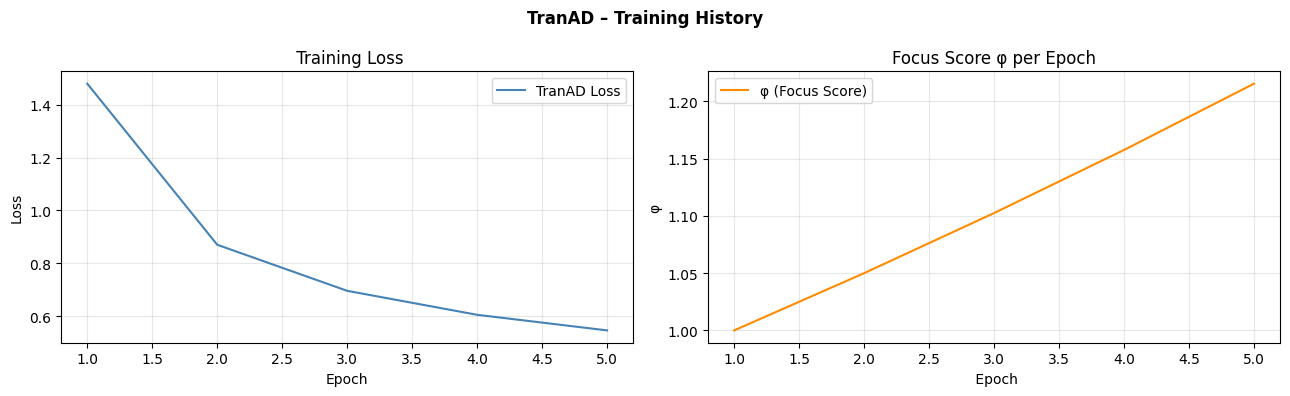

First ECG shape: torch.Size([1, 1000, 12])
First ECG label: tensor(0)


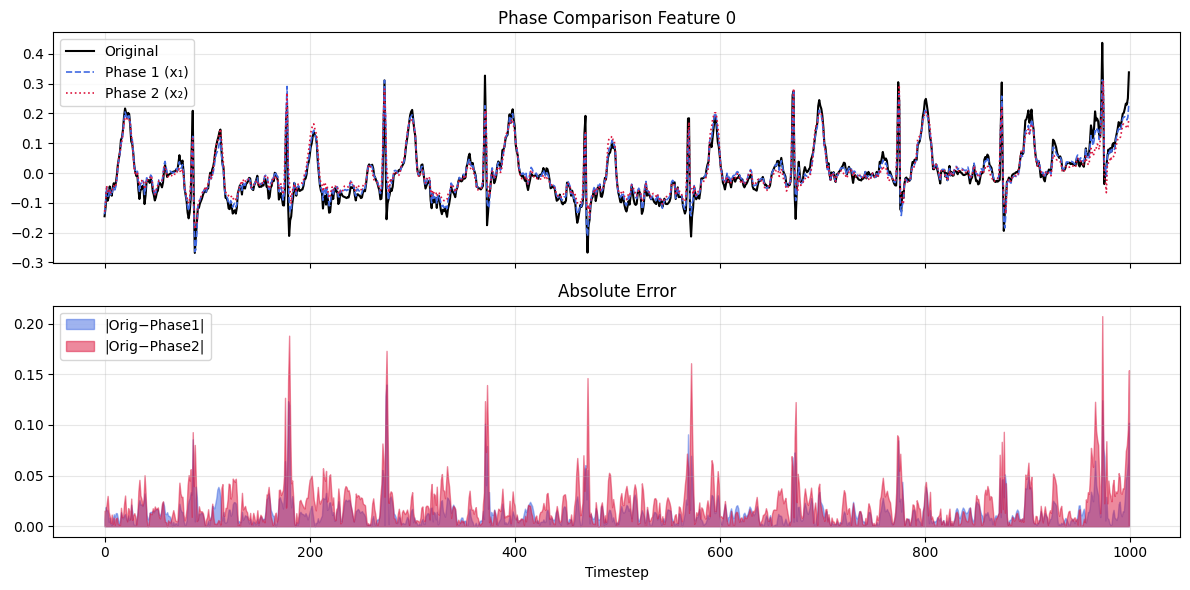

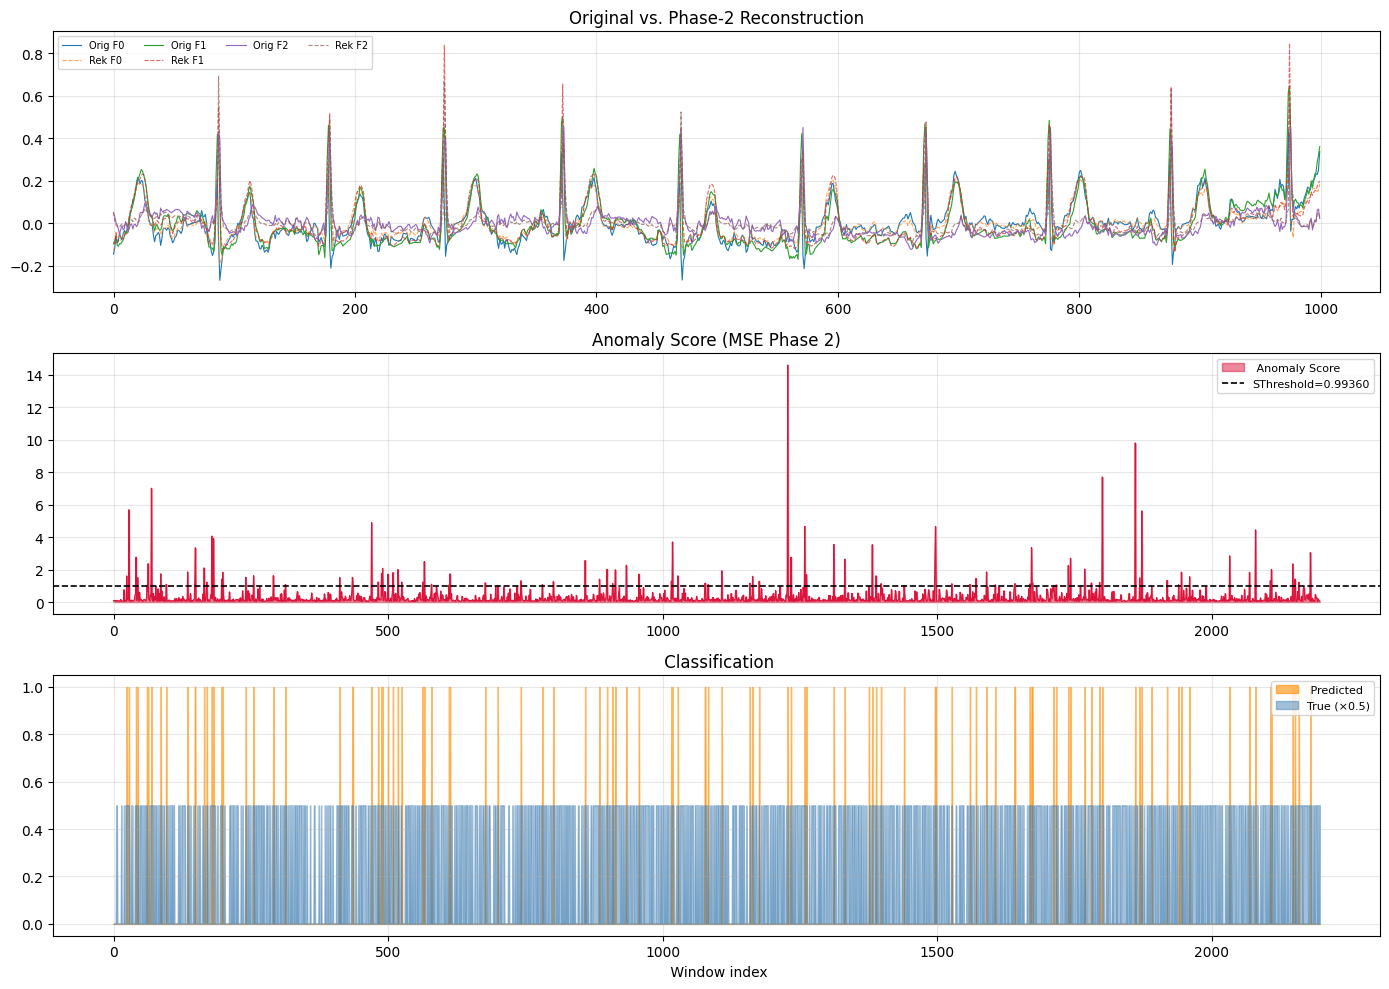

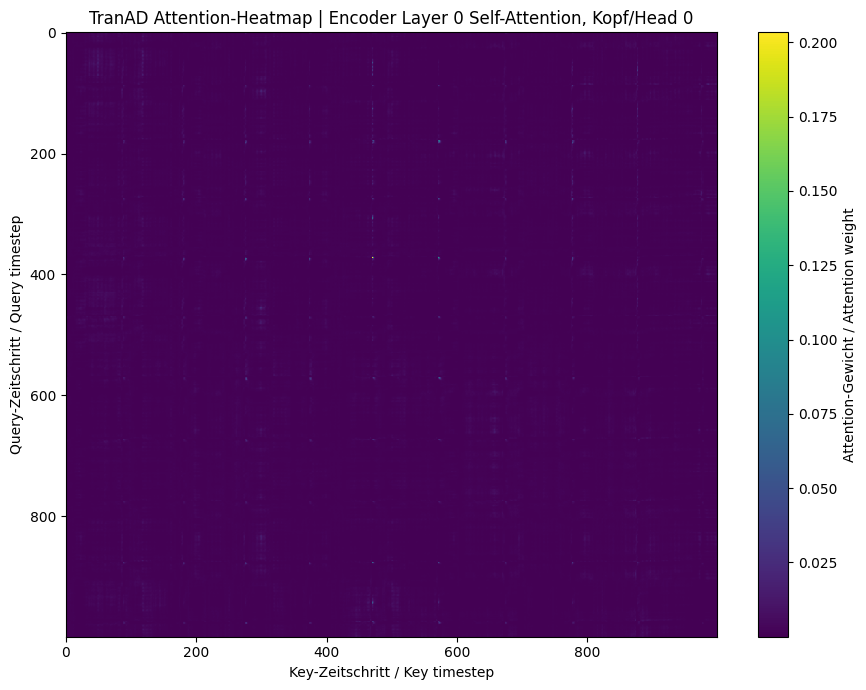

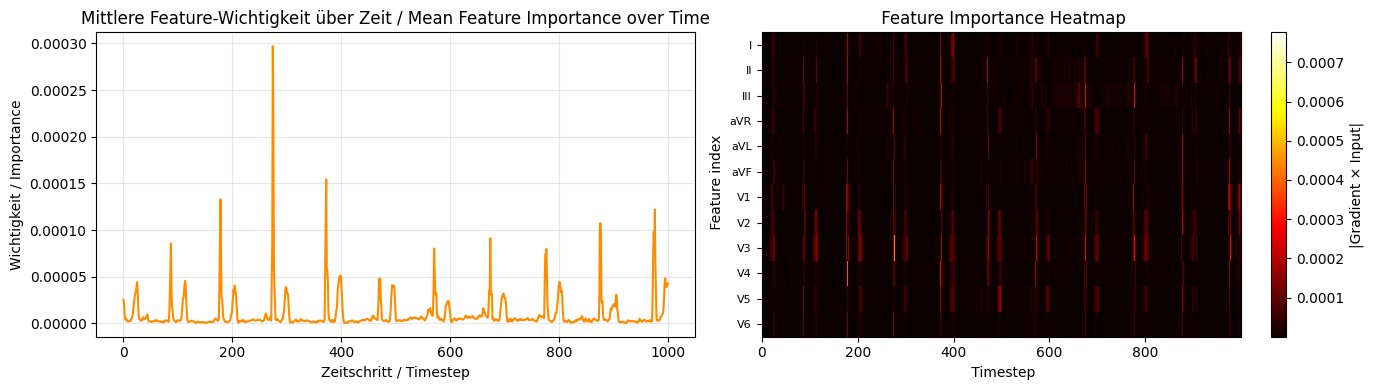

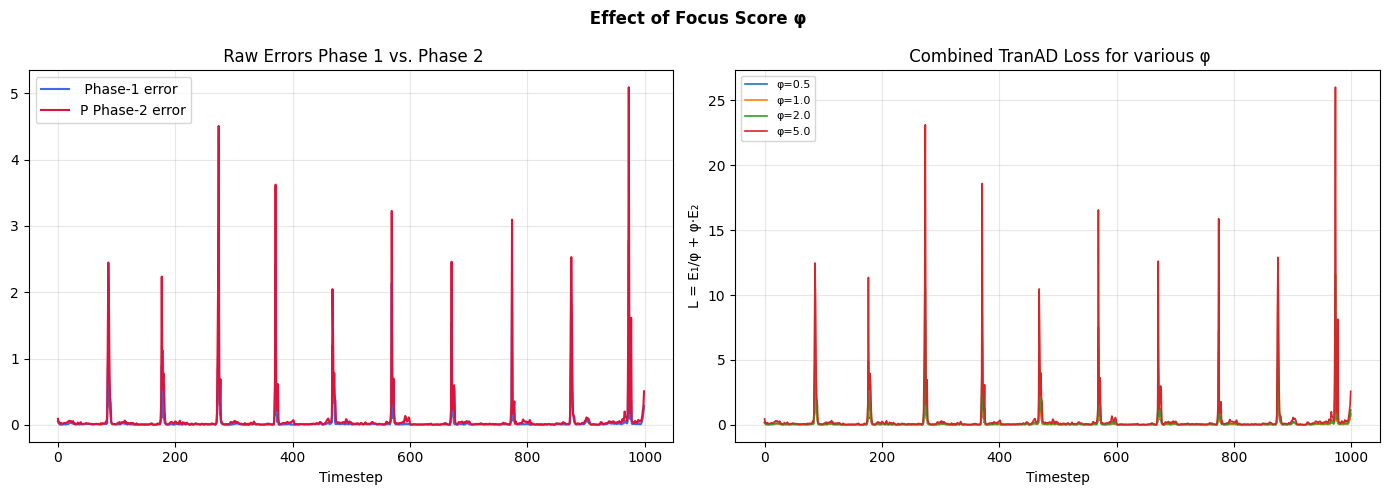


TranAD PTB-XL explainability complete.


In [54]:
# Explainability


print("\n── Explainability ──────────────────────────────────────────────────")

Explainer = TranADExplainability(TranAD)
ECG_LEADS = [
    "I", "II", "III",
    "aVR", "aVL", "aVF",
    "V1", "V2", "V3", "V4", "V5", "V6"
]


# 7a. Training history
Explainer.ShowTrainingHistory()

# 7b. Get first ECG record from test set
FirstECG, FirstLabel = test_dataset[0]
FirstECG = FirstECG.unsqueeze(0).to(TranAD.Device)

print("First ECG shape:", FirstECG.shape)
print("First ECG label:", FirstLabel)

# 7c. Phase-1 vs Phase-2 comparison for one ECG lead
Explainer.ShowPhaseComparison(
    FirstECG,
    FeatureIndex=0,
    DatasetForInverseNorm=test_dataset
)

# 7d. Reconstruction error visualization
with torch.no_grad():
    _, Rec2 = TranAD.Network(FirstECG)

OrigNP = test_dataset.InverseNormalization(
    FirstECG[0].cpu().numpy()
)

RecNP = test_dataset.InverseNormalization(
    Rec2[0].cpu().numpy()
)

Explainer.ShowReconstructionError(
    OriginalData      = OrigNP,
    ReconstructedData = RecNP,
    AnomalyScores     = AnomalyScores,
    TrueLabels        = y_test,
    Threshold         = TranAD.AnomalyThreshold,
)

# 7e. Attention heatmap
Explainer.ShowAttentionHeatmap(
    FirstECG,
    LayerIndex=0,
    HeadIndex=0,
    Component="Encoder"
)

# 7f. Feature importance / lead importance
Explainer.ShowFeatureImportance(
    FirstECG,
    FeatureNames=ECG_LEADS,
)

# 7g. Focus score effect
Explainer.ShowFocusScoreEffect(
    FirstECG,
    FocusScoreList=[0.5, 1.0, 2.0, 5.0]
)

print("\nTranAD PTB-XL explainability complete.")

In [ ]:
# ── TranAD Attention-based Explainability ─────────────────────

import numpy as np

print("\n── TranAD Attention-based Explainability ─────────────────────")

Explainer = TranADExplainability(TranAD)

# Select meaningful samples, not arbitrary first samples
correct_normal = np.where(
    (y_test == 0) & (BinaryPredictions == 0)
)[0]

correct_anomaly = np.where(
    (y_test == 1) & (BinaryPredictions == 1)
)[0]

NormalIndex = correct_normal[
    np.argmin(AnomalyScores[correct_normal])
]

AnomalousIndex = correct_anomaly[
    np.argmax(AnomalyScores[correct_anomaly])
]

print("Selected normal index:", NormalIndex)
print("Normal score:", AnomalyScores[NormalIndex])

print("Selected anomalous index:", AnomalousIndex)
print("Anomalous score:", AnomalyScores[AnomalousIndex])

NormalECG, NormalLabel = test_dataset[NormalIndex]
AnomalousECG, AnomalousLabel = test_dataset[AnomalousIndex]

NormalECG = NormalECG.unsqueeze(0).to(TranAD.Device)
AnomalousECG = AnomalousECG.unsqueeze(0).to(TranAD.Device)

Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    Component="Encoder",
    LayerIndex=0,
    HeadIndex=None,
    Percentile=99.0,
)